# 1. Photometric stereo

Recover albedo, normals, and shape of a face from seven images taken under different lights. The math and the discussion of the results are in the report.

## Setup

| Symbol | Shape | Meaning |
|---|---|---|
| `I` | 7 × P | stacked luminance images |
| `L` | 3 × 7 | light directions, one per column |
| `B` | 3 × P | pseudo-normals (albedo × normal) |
| `A` | P | albedo |
| `N` | 3 × P | unit normals |

Image model: $I = L^T B$.

In [192]:
import os

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
from skimage import io
from skimage.filters import sobel
from skimage.registration import phase_cross_correlation
from skimage.transform import downscale_local_mean
from scipy.ndimage import gaussian_filter
from scipy.ndimage import shift as shift_image
from scipy.ndimage import binary_fill_holes, binary_erosion, label

from cp_hw5 import integrate_poisson, integrate_frankot, load_sources

# Folder for figures used in the report
REPORT_IMAGE_DIR = "../data/report_images"
os.makedirs(REPORT_IMAGE_DIR, exist_ok=True)

### Helper functions

Shared by Part 1 and Part 2: loading luminance, splitting pseudo-normals into albedo and normals, converting normals to depth gradients, and applying a GBR.

In [193]:
# Load a linear sRGB TIFF and return its luminance (Y of XYZ)
def load_luminance(path):
    # Scale 16-bit values to [0, 1], keeping the data linear
    image = io.imread(path).astype(np.float64)
    image = image / 65535.0

    red = image[:, :, 0]
    green = image[:, :, 1]
    blue = image[:, :, 2]

    # Y row of the linear sRGB -> XYZ matrix (skimage's rgb2xyz would re-linearize)
    luminance = 0.2126 * red + 0.7152 * green + 0.0722 * blue
    return luminance


# Split 3 x P pseudo-normals into albedo (length) and unit normals (direction)
def pseudonormals_to_albedo_normals(B):
    epsilon = 1e-8

    albedo = np.linalg.norm(B, axis=0)
    normals = B / (albedo + epsilon)
    return albedo, normals


# Reshape a P vector to H x W, or a 3 x P matrix to H x W x 3
def to_image(matrix, height, width):
    if matrix.ndim == 1:
        return matrix.reshape(height, width)
    return matrix.T.reshape(height, width, 3)


# Gaussian blur each channel separately (a 3D kernel would mix channels)
def blur_each_channel(image, sigma):
    blurred = np.zeros_like(image)
    for channel in range(image.shape[2]):
        blurred[:, :, channel] = gaussian_filter(image[:, :, channel], sigma=sigma)
    return blurred


# Convert normals to depth derivatives; epsilon avoids dividing by n_z near 0
def normals_to_depth_gradients(normals, height, width, epsilon=1e-3, max_slope=10):
    normal_image = to_image(normals, height, width)
    normal_x = normal_image[:, :, 0]
    normal_y = normal_image[:, :, 1]
    normal_z = normal_image[:, :, 2]

    depth_dx = -normal_x / (normal_z + epsilon)
    depth_dy = -normal_y / (normal_z + epsilon)

    # Clip so a few pixels with n_z near 0 cannot dominate the integration
    depth_dx = np.clip(depth_dx, -max_slope, max_slope)
    depth_dy = np.clip(depth_dy, -max_slope, max_slope)
    return depth_dx, depth_dy


# Pseudo-normals -> unit normals -> depth derivatives -> Poisson-integrated depth
def pseudonormals_to_depth(B, height, width):
    _, normals = pseudonormals_to_albedo_normals(B)
    depth_dx, depth_dy = normals_to_depth_gradients(normals, height, width)
    return integrate_poisson(depth_dx.copy(), depth_dy.copy())


# Apply a GBR transform G(mu, nu, lam) to pseudo-normals: B -> G^-T B
def apply_gbr(B, mu, nu, lam):
    G = np.array([[1.0, 0.0, 0.0],
                  [0.0, 1.0, 0.0],
                  [mu,  nu,  lam]])
    G_inverse_transpose = np.linalg.inv(G).T
    return G_inverse_transpose @ B

#### Display helpers

Normals are shown as RGB with $(n + 1)/2$, and the albedo is scaled up so it is visible. Surfaces are shaded with a `LightSource` and plotted as $-Z$ (our z-axis points down). Passing `filename=` saves the figure to `report_images/`.

In [194]:
def normalize_image(image):
    min_value = image.min()
    max_value = image.max()
    return (image - min_value) / (max_value - min_value)


def normals_to_rgb(normal_image):
    # Map [-1, 1] to [0, 1] for display
    rgb = (normal_image + 1) / 2
    return np.clip(rgb, 0, 1)


def save_figure(figure, filename):
    # Save a figure into the report folder (skipped when filename is None)
    if filename is not None:
        figure.savefig(os.path.join(REPORT_IMAGE_DIR, filename), bbox_inches="tight", dpi=150)


def show_albedo_and_normals(albedo, normals, height, width, title, albedo_scale=10, filename=None):
    albedo_image = to_image(albedo, height, width)
    normal_image = to_image(normals, height, width)

    # Figure height follows the image's aspect ratio
    figure, axes = plt.subplots(1, 2, figsize=(8, 4 * height / width + 0.8))

    axes[0].imshow(np.clip(albedo_image * albedo_scale, 0, 1), cmap="gray")
    axes[0].set_title(f"Albedo (x{albedo_scale})")
    axes[0].axis("off")

    axes[1].imshow(normals_to_rgb(normal_image))
    axes[1].set_title("Normals")
    axes[1].axis("off")

    figure.suptitle(title)
    save_figure(figure, filename)
    plt.show()


def show_depth(depth, title, figure_width=4, filename=None):
    height, width = depth.shape
    figure = plt.figure(figsize=(figure_width, figure_width * height / width + 0.5))
    plt.imshow(normalize_image(depth), cmap="gray")
    plt.title(title)
    plt.axis("off")
    save_figure(figure, filename)
    plt.show()


def draw_surface(axis, depth, title, elevation, azimuth):
    height, width = depth.shape
    x, y = np.meshgrid(np.arange(width), np.arange(height))

    # Shade the surface; use -depth because our z-axis points down
    light_source = LightSource()
    shading = light_source.shade(-depth, plt.cm.gray)
    axis.plot_surface(x, y, -depth, facecolors=shading, rstride=4, cstride=4, linewidth=0)

    # True proportions, so a deeper or flatter relief is visible
    axis.set_box_aspect((width, height, depth.max() - depth.min()))
    axis.view_init(elev=elevation, azim=azimuth)
    axis.set_title(title)
    axis.axis("off")


def show_surface(depth, title, elevation=30, azimuth=-60, filename=None):
    figure = plt.figure(figsize=(6, 6))
    axis = figure.add_subplot(projection="3d")
    draw_surface(axis, depth, title, elevation, azimuth)
    save_figure(figure, filename)
    plt.show()


def show_surfaces_in_row(depths, titles, elevation=30, azimuth=-60, filename=None):
    figure = plt.figure(figsize=(4 * len(depths), 4))
    for index in range(len(depths)):
        axis = figure.add_subplot(1, len(depths), index + 1, projection="3d")
        draw_surface(axis, depths[index], titles[index], elevation, azimuth)
    save_figure(figure, filename)
    plt.show()

## Initials

Load the seven images, keep the luminance of each, and stack them as the rows of `I`.

Image 1 range: 0.0017 to 0.4976
Image 2 range: 0.0000 to 0.7853
Image 3 range: 0.0000 to 0.4503
Image 4 range: 0.0000 to 0.5698
Image 5 range: 0.0000 to 0.5551
Image 6 range: 0.0000 to 0.5473
Image 7 range: 0.0000 to 0.5269
Image size (H, W): (431, 369)
Number of pixels P: 159039
I shape: (7, 159039)


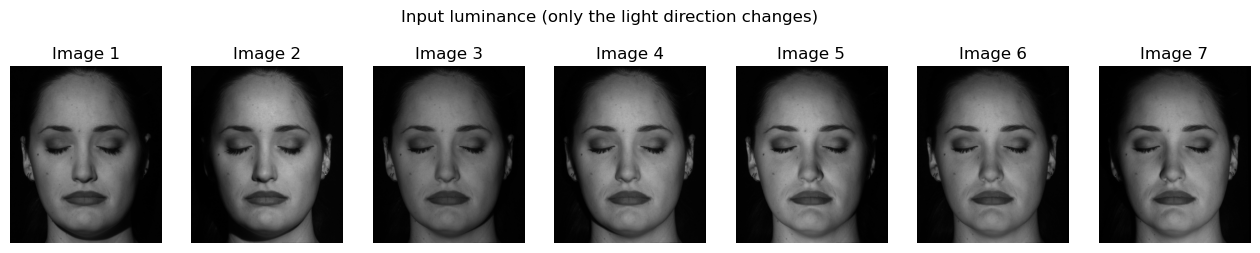

In [195]:
num_images = 7

# Load the luminance channel of each image
luminance_images = []
for image_index in range(1, num_images + 1):
    path = f"../data/input_{image_index}.tif"
    luminance = load_luminance(path)
    luminance_images.append(luminance)
    print(f"Image {image_index} range: {luminance.min():.4f} to {luminance.max():.4f}")

H, W = luminance_images[0].shape
P = H * W
print("Image size (H, W):", (H, W))
print("Number of pixels P:", P)

# Flatten each image into one row of I
rows = []
for luminance in luminance_images:
    rows.append(luminance.flatten())
I = np.stack(rows, axis=0)
print("I shape:", I.shape)

# Show the seven luminance images on a shared brightness scale
max_luminance = I.max()

figure, axes = plt.subplots(1, num_images, figsize=(16, 3))
for image_index in range(num_images):
    axes[image_index].imshow(luminance_images[image_index], cmap="gray", vmin=0, vmax=max_luminance)
    axes[image_index].set_title(f"Image {image_index + 1}")
    axes[image_index].axis("off")

figure.suptitle("Input luminance (only the light direction changes)")
save_figure(figure, "input_luminance.png")
plt.show()

The images look very similar: every light is close to the viewing direction, so only the shading around the nose, cheeks, and eyes changes.

## Uncalibrated photometric stereo

Without the lights, `I` is factored directly. In the model, `I` has rank 3, so the top 3 singular values of an SVD give the best rank-3 fit, split into lights `L_e` and pseudo-normals `B_e`. This split is only defined up to an invertible 3 × 3 matrix `Q`.

Singular values: [252.13  29.99  21.01   6.41   4.84   3.82   3.11]
Energy in top 3: 0.9986
L_e shape: (3, 7)
B_e shape: (3, 159039)
Relative reconstruction error (L_e, B_e): 0.0370
A_e range: 0.0006 to 0.1095


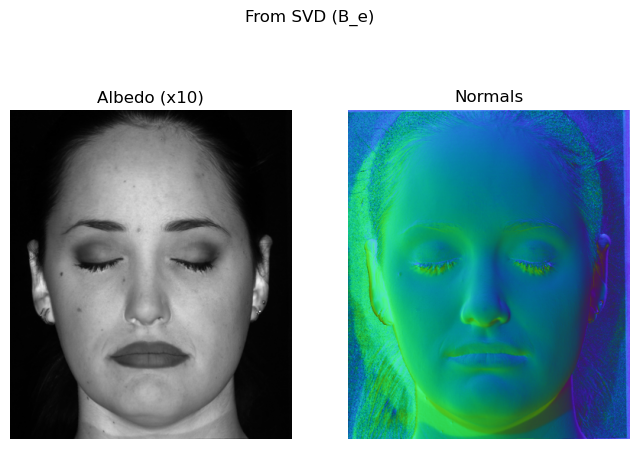

det(Q): 0.515
Relative reconstruction error (L_Q, B_Q): 0.0370
A_Q range: 0.0007 to 0.1751


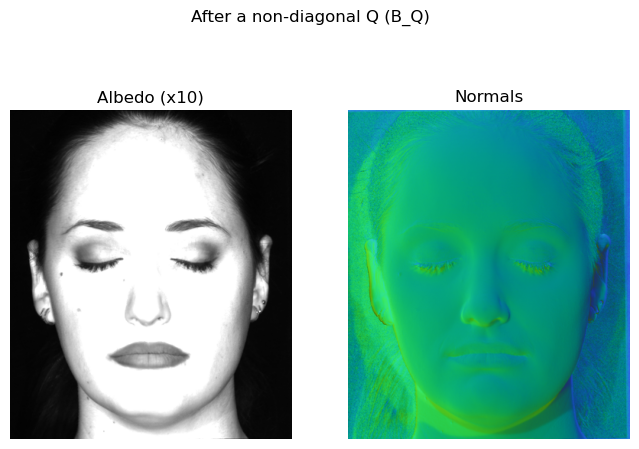

In [196]:
# Thin SVD of I (full_matrices=False avoids a P x P matrix for V)
U, S, Vt = np.linalg.svd(I, full_matrices=False)
print("Singular values:", np.round(S, 2))

# Fraction of I explained by a rank-3 fit
rank3_energy = np.sum(S[:3] ** 2) / np.sum(S ** 2)
print(f"Energy in top 3: {rank3_energy:.4f}")

# Split the square root of the top 3 singular values between the two factors
sqrt_singular = np.diag(np.sqrt(S[:3]))
L_e = (U[:, :3] @ sqrt_singular).T
B_e = sqrt_singular @ Vt[:3, :]
print("L_e shape:", L_e.shape)
print("B_e shape:", B_e.shape)

# Relative error of the rank-3 reconstruction
reconstruction = L_e.T @ B_e
difference = I - reconstruction
relative_error = np.linalg.norm(difference) / np.linalg.norm(I)
print(f"Relative reconstruction error (L_e, B_e): {relative_error:.4f}")

# Albedo and normals from the SVD pseudo-normals
A_e, N_e = pseudonormals_to_albedo_normals(B_e)
print(f"A_e range: {A_e.min():.4f} to {A_e.max():.4f}")
show_albedo_and_normals(A_e, N_e, H, W, "From SVD (B_e)", filename="svd_albedo_normals.png")

# Any invertible Q gives another valid factorization: L_Q = Q L_e, B_Q = Q^-T B_e
Q = np.array([[0.5, 0.25, 0.0],
              [0.0, 1.0,  0.3],
              [0.2, 0.0,  1.0]])
print("det(Q):", round(np.linalg.det(Q), 3))

L_Q = Q @ L_e
B_Q = np.linalg.inv(Q).T @ B_e

# The new factors reproduce I exactly as well as the SVD factors
reconstruction_Q = L_Q.T @ B_Q
difference_Q = I - reconstruction_Q
relative_error_Q = np.linalg.norm(difference_Q) / np.linalg.norm(I)
print(f"Relative reconstruction error (L_Q, B_Q): {relative_error_Q:.4f}")

# Albedo and normals from the transformed pseudo-normals
A_Q, N_Q = pseudonormals_to_albedo_normals(B_Q)
print(f"A_Q range: {A_Q.min():.4f} to {A_Q.max():.4f}")
show_albedo_and_normals(A_Q, N_Q, H, W, "After a non-diagonal Q (B_Q)", filename="q_albedo_normals.png")

The top 3 singular values dominate, so the Lambertian model fits well. The albedo already looks right, but the normal colors are off, and applying another `Q` changes both while fitting `I` equally well. The next section narrows down `Q`.

## Enforcing integrability

Real normals come from a surface, so they must be integrable. Requiring this removes most of the ambiguity in `Q`, leaving only a GBR $(\mu, \nu, \lambda)$. `enforce_integrability` follows the handout:

1. reshape `B_e` into an image and blur each channel (for the derivatives only)
2. build one linear equation per pixel (Eqs. 7–12) and solve the system with SVD
3. build `Delta` (Eq. 13) and apply it to `B_e`

The result depends strongly on the blur width σ, so we compare several values.

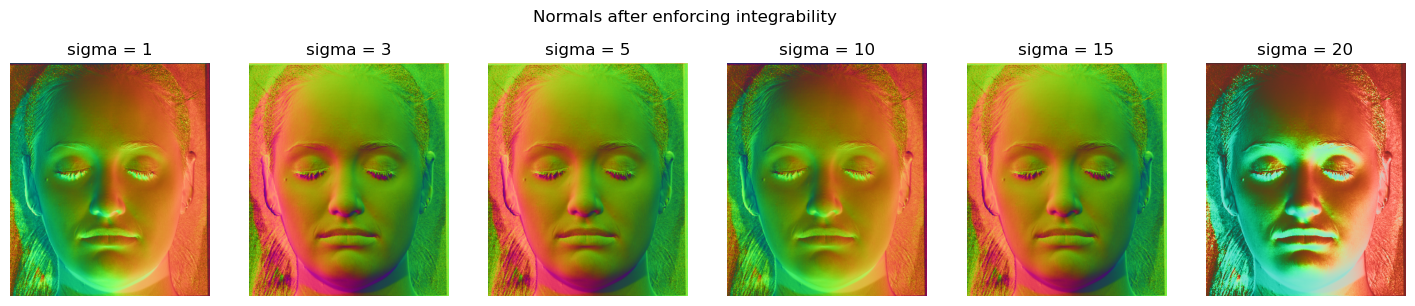

In [197]:
# Find Delta that makes the normals integrable and return B_int = Delta^-1 B_e
def enforce_integrability(B_e, height, width, sigma, mask=None):
    # Pseudo-normal image, plus a blurred copy used only for derivatives
    B_e_image = to_image(B_e, height, width)
    B_e_blurred = blur_each_channel(B_e_image, sigma)

    # Derivatives of each blurred channel (np.gradient returns d/dy first)
    dB_dx = np.zeros_like(B_e_blurred)
    dB_dy = np.zeros_like(B_e_blurred)
    for channel in range(3):
        derivative_y, derivative_x = np.gradient(B_e_blurred[:, :, channel])
        dB_dx[:, :, channel] = derivative_x
        dB_dy[:, :, channel] = derivative_y

    # Six constraint columns (Eqs. 7-12) using the unblurred b_e
    b1 = B_e_image[:, :, 0]
    b2 = B_e_image[:, :, 1]
    b3 = B_e_image[:, :, 2]
    A1 = b1 * dB_dx[:, :, 1] - b2 * dB_dx[:, :, 0]
    A2 = b1 * dB_dx[:, :, 2] - b3 * dB_dx[:, :, 0]
    A3 = b2 * dB_dx[:, :, 2] - b3 * dB_dx[:, :, 1]
    A4 = -b1 * dB_dy[:, :, 1] + b2 * dB_dy[:, :, 0]
    A5 = -b1 * dB_dy[:, :, 2] + b3 * dB_dy[:, :, 0]
    A6 = -b2 * dB_dy[:, :, 2] + b3 * dB_dy[:, :, 1]

    # P x 6 system: one row per pixel
    columns = [A1.flatten(), A2.flatten(), A3.flatten(), A4.flatten(), A5.flatten(), A6.flatten()]
    A_system = np.stack(columns, axis=1)

    # Optionally keep only the rows of object pixels
    if mask is not None:
        A_system = A_system[mask.flatten()]

    # Solve A x = 0: right singular vector with the smallest singular value
    _, _, system_Vt = np.linalg.svd(A_system, full_matrices=False)
    x1, x2, x3, x4, x5, x6 = system_Vt[-1]

    # Delta from Eq. 13; the fixed third column is the remaining GBR freedom
    Delta = np.array([[-x3,  x6, 1.0],
                      [ x2, -x5, 0.0],
                      [-x1,  x4, 0.0]])

    B_int = np.linalg.inv(Delta) @ B_e
    return B_int, Delta


# Run the method for several blur widths and show the normals in one row
sigma_values = [1, 3, 5, 10, 15, 20]
figure, axes = plt.subplots(1, len(sigma_values), figsize=(3 * len(sigma_values), 3.5))
for index in range(len(sigma_values)):
    B_sigma, _ = enforce_integrability(B_e, H, W, sigma_values[index])
    _, N_sigma = pseudonormals_to_albedo_normals(B_sigma)
    axes[index].imshow(normals_to_rgb(to_image(N_sigma, H, W)))
    axes[index].set_title(f"sigma = {sigma_values[index]}")
    axes[index].axis("off")

figure.suptitle("Normals after enforcing integrability")
save_figure(figure, "sigma_comparison.png")
plt.show()

### Result for the chosen σ

The shape is still only known up to a GBR, including an inside-out flip, which can only be judged after integrating.

Delta:
 [[-0.1674  0.2899  1.    ]
 [ 0.527  -0.2233  0.    ]
 [ 0.1696  0.7291  0.    ]]
det(Delta): 0.4221
A_final range: 0.0008 to 0.1872


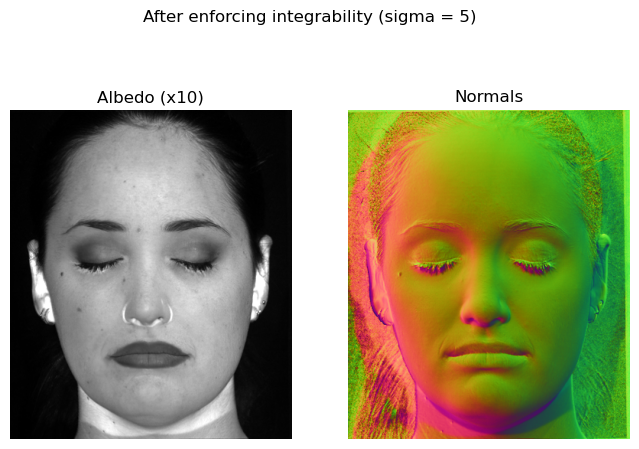

In [198]:
# Chosen blur width (from the comparison above)
sigma = 5
B_final, Delta = enforce_integrability(B_e, H, W, sigma)
print("Delta:\n", np.round(Delta, 4))
print("det(Delta):", round(np.linalg.det(Delta), 4))

A_final, N_final = pseudonormals_to_albedo_normals(B_final)
print(f"A_final range: {A_final.min():.4f} to {A_final.max():.4f}")

show_albedo_and_normals(A_final, N_final, H, W, f"After enforcing integrability (sigma = {sigma})",
                        filename="integrable_albedo_normals.png")

## Normal integration

Convert normals to depth derivatives ($-n_x/n_z$, $-n_y/n_z$), with a small ε and clipping to avoid huge slopes, then integrate with the Poisson and Frankot–Chellappa integrators.

The direct result is inside-out, and the remaining GBR $f \to \lambda f + \mu x + \nu y$ is chosen from the data: μ and ν make the average normal face the camera, the sign of λ fixes the flip, and |λ| is picked by eye from a sweep.

Z_poisson range: -227.03 to 93.49
Z_frankot range: -105.98 to 134.84


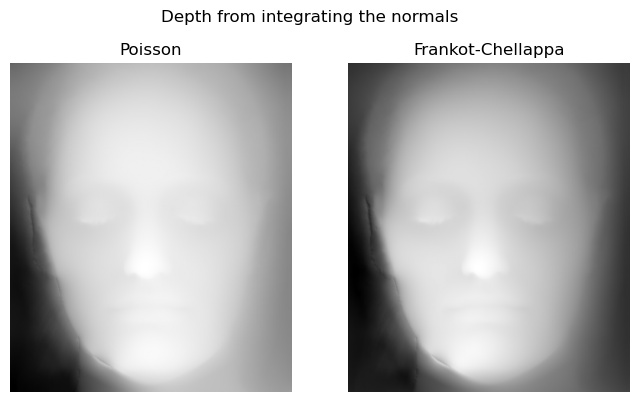

In [199]:
# Depth derivatives from the integrable normals
depth_dx, depth_dy = normals_to_depth_gradients(N_final, H, W)

# Integrate with both methods (copies, since integrate_poisson edits its inputs)
Z_poisson = integrate_poisson(depth_dx.copy(), depth_dy.copy())
Z_frankot = integrate_frankot(depth_dx, depth_dy)
print(f"Z_poisson range: {Z_poisson.min():.2f} to {Z_poisson.max():.2f}")
print(f"Z_frankot range: {Z_frankot.min():.2f} to {Z_frankot.max():.2f}")

# Compare the two depth maps, each normalized to [0, 1]
figure, axes = plt.subplots(1, 2, figsize=(8, 4.5))

axes[0].imshow(normalize_image(Z_poisson), cmap="gray")
axes[0].set_title("Poisson")
axes[0].axis("off")

axes[1].imshow(normalize_image(Z_frankot), cmap="gray")
axes[1].set_title("Frankot-Chellappa")
axes[1].axis("off")

figure.suptitle("Depth from integrating the normals")
save_figure(figure, "depth_poisson_vs_frankot.png")
plt.show()

Mean normal (x, y, z): [ 0.018  0.029 -0.716]
Tilt to remove: -0.03 along x, -0.04 along y
Sign of lam: -1.0


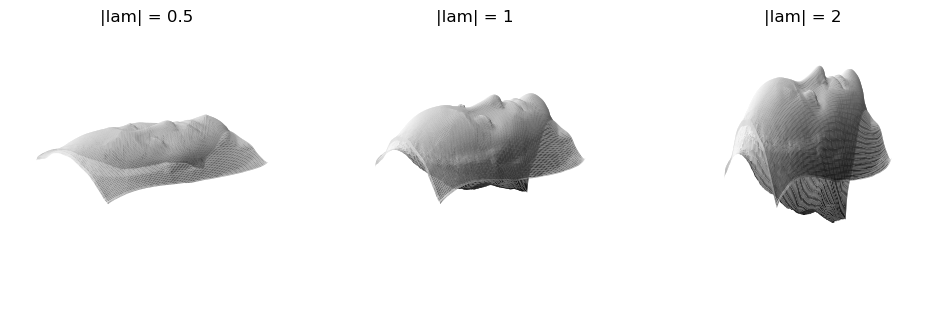

Chosen GBR: mu = 0.03, nu = 0.04, lam = -1.00


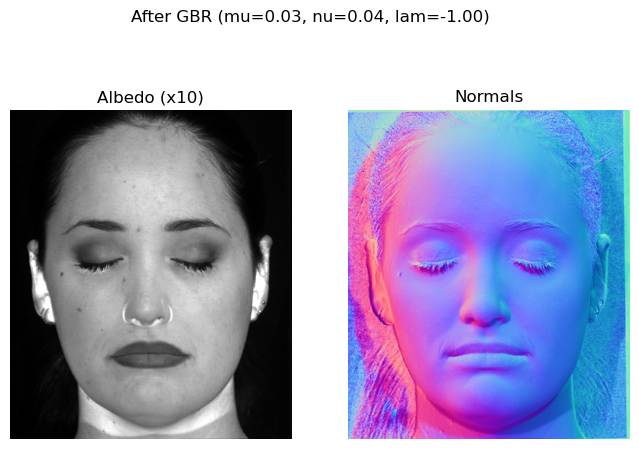

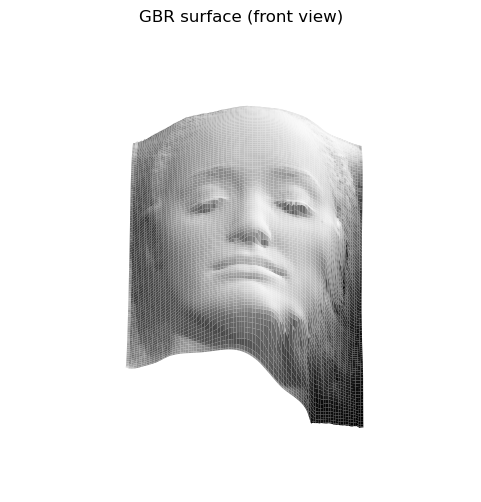

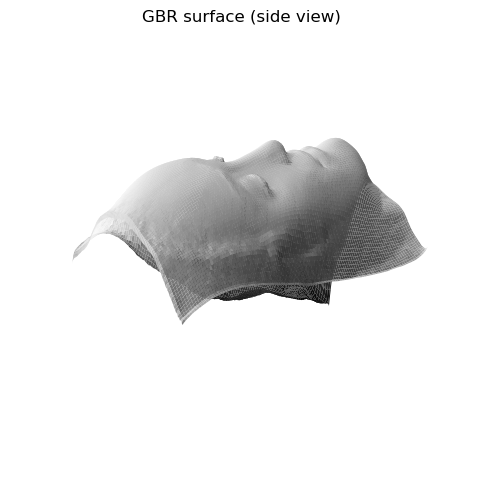

In [200]:
# Average normal direction over the image
mean_normal = np.mean(N_final, axis=1)
print("Mean normal (x, y, z):", np.round(mean_normal, 3))

# Tilt that sends the mean normal to +z (in slope units)
tilt_x = mean_normal[0] / mean_normal[2]
tilt_y = mean_normal[1] / mean_normal[2]
print(f"Tilt to remove: {tilt_x:.2f} along x, {tilt_y:.2f} along y")

# The sign of lam must match n_z so the face is not inside-out
lam_sign = np.sign(mean_normal[2])
print("Sign of lam:", lam_sign)

# Sweep the depth scale with the tilt removed
lam_magnitudes = [0.5, 1, 2]
sweep_depths = []
sweep_titles = []
for lam_magnitude in lam_magnitudes:
    lam = lam_sign * lam_magnitude
    mu = lam * tilt_x
    nu = lam * tilt_y
    B_gbr = apply_gbr(B_final, mu, nu, lam)
    sweep_depths.append(pseudonormals_to_depth(B_gbr, H, W))
    sweep_titles.append(f"|lam| = {lam_magnitude}")
show_surfaces_in_row(sweep_depths, sweep_titles, elevation=20, azimuth=-30)

# Chosen depth scale (edit after looking at the sweep above)
lam_chosen = lam_sign * 1
mu_chosen = lam_chosen * tilt_x
nu_chosen = lam_chosen * tilt_y
print(f"Chosen GBR: mu = {mu_chosen:.2f}, nu = {nu_chosen:.2f}, lam = {lam_chosen:.2f}")

B_gbr = apply_gbr(B_final, mu_chosen, nu_chosen, lam_chosen)
A_gbr, N_gbr = pseudonormals_to_albedo_normals(B_gbr)
Z_gbr = pseudonormals_to_depth(B_gbr, H, W)

show_albedo_and_normals(A_gbr, N_gbr, H, W,
                        f"After GBR (mu={mu_chosen:.2f}, nu={nu_chosen:.2f}, lam={lam_chosen:.2f})",
                        filename="gbr_albedo_normals.png")
show_surface(Z_gbr, "GBR surface (front view)", elevation=60, azimuth=90, filename="gbr_surface_front.png")
show_surface(Z_gbr, "GBR surface (side view)", elevation=20, azimuth=-30, filename="gbr_surface_side.png")

## Calibrated photometric stereo

With the measured lights, $I = L^T B$ is a plain least-squares problem, solved for all pixels at once with `np.linalg.lstsq`. No integrability step or GBR is needed. The lights point along $-z$, so normals facing the camera have $n_z < 0$.

Relative reconstruction error (calibrated): 0.0461
A_cal range: 0.0054 to 1.6152
Fraction of n_z < 0: 1.0


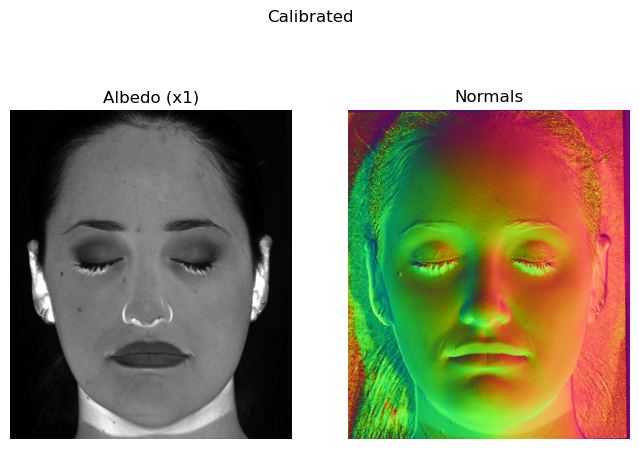

In [201]:
# Known light directions: one light per column
S_sources = load_sources()
L = S_sources.T

# Least squares for all pixels at once: (7 x 3) @ (3 x P) = (7 x P)
B_cal, _, _, _ = np.linalg.lstsq(L.T, I, rcond=None)

# Relative error of the calibrated fit (compare with 3.7% for the rank-3 SVD)
difference_cal = I - L.T @ B_cal
relative_error_cal = np.linalg.norm(difference_cal) / np.linalg.norm(I)
print(f"Relative reconstruction error (calibrated): {relative_error_cal:.4f}")

A_cal, N_cal = pseudonormals_to_albedo_normals(B_cal)
print(f"A_cal range: {A_cal.min():.4f} to {A_cal.max():.4f}")
print("Fraction of n_z < 0:", round(np.mean(N_cal[2] < 0), 3))

show_albedo_and_normals(A_cal, N_cal, H, W, "Calibrated", albedo_scale=1,
                        filename="calibrated_albedo_normals.png")

Z_cal range: -130.95 to 352.57


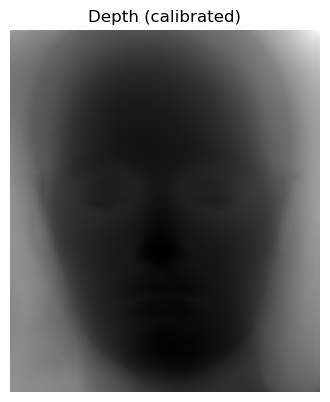

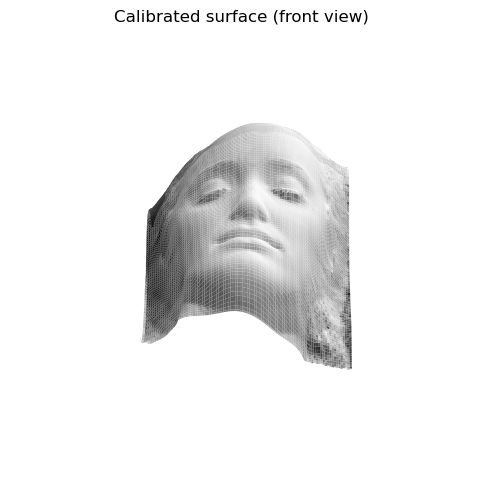

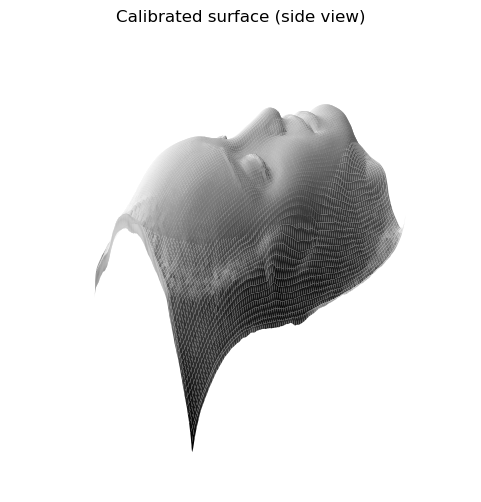

In [202]:
# Depth from the calibrated normals (same pipeline as the uncalibrated case)
Z_cal = pseudonormals_to_depth(B_cal, H, W)
print(f"Z_cal range: {Z_cal.min():.2f} to {Z_cal.max():.2f}")

show_depth(Z_cal, "Depth (calibrated)", filename="calibrated_depth.png")

# Same two views as the uncalibrated surface, as in Figure 4
show_surface(Z_cal, "Calibrated surface (front view)", elevation=60, azimuth=90,
             filename="calibrated_surface_front.png")
show_surface(Z_cal, "Calibrated surface (side view)", elevation=20, azimuth=-30,
             filename="calibrated_surface_side.png")

The fit error is a little higher than the rank-3 SVD, as expected with fixed lights. The normals are integrated exactly as in the uncalibrated case.

# 2. Capture and reconstruct your own shapes

## Load, align, and prepare the images

Each light direction becomes one row of `I`:

- **align** each frame to a reference (the camera turned slightly between groups), using edge images so the changing light does not matter
- **average** repeated shots and **subtract** the light-off frame
- **crop and downsample** to at most 512 px wide
- **record clipped pixels** (saturated in any frame), to leave out later

The RAW files are converted once with dcraw (see the README).

I_paper shape: (7, 88576)  image size (H, W): (173, 512)
Paper clipped fraction: 0.030
I_sneaker shape: (7, 62775)  image size (H, W): (155, 405)
Sneaker clipped fraction: 0.003


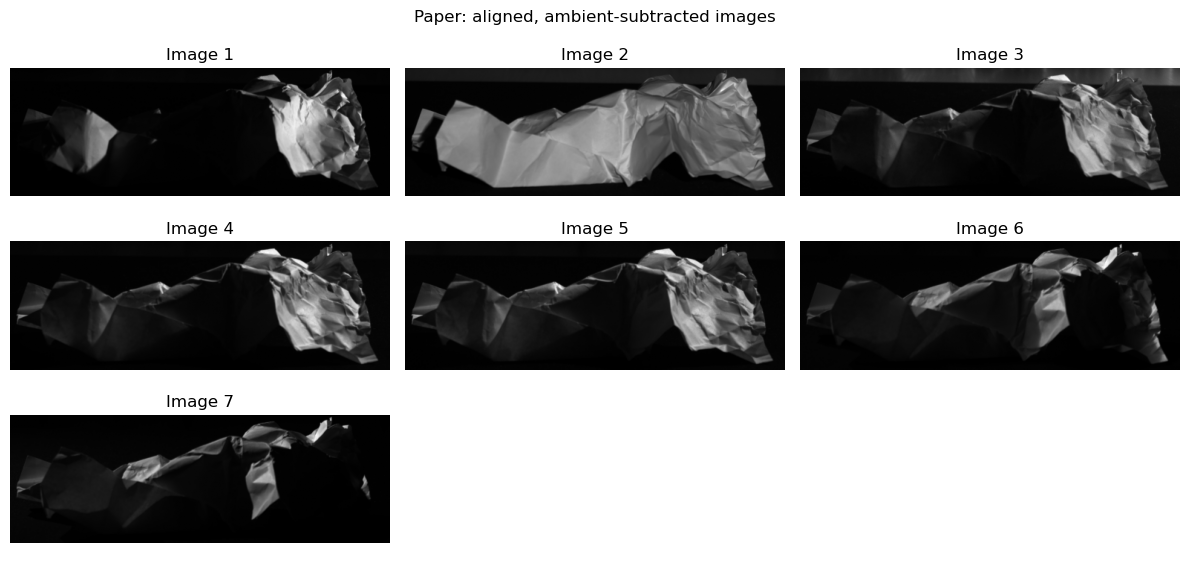

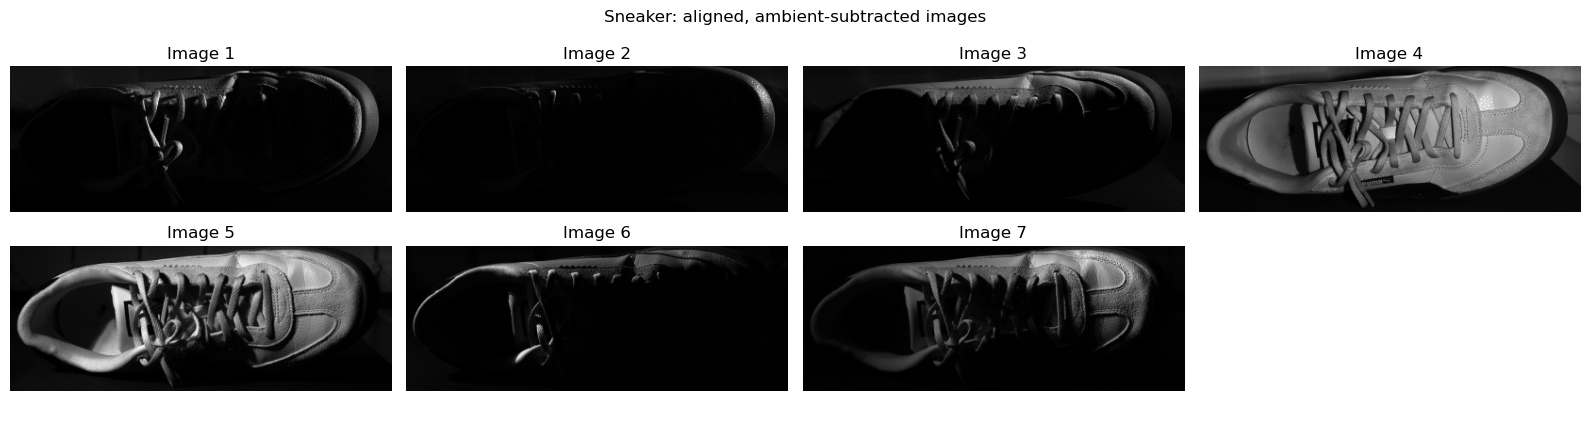

In [203]:
# Edge image used for alignment (edges stay in place when the lighting changes)
def edge_image(image):
    log_image = np.log(image + 1e-3)
    return sobel(log_image)


# Shift an image so it lines up with a reference image (camera moved between groups)
def align_to_reference(image, reference):
    reference_edges = edge_image(reference)
    image_edges = edge_image(image)
    shift, _, _ = phase_cross_correlation(reference_edges, image_edges, upsample_factor=4)
    aligned = shift_image(image, shift, order=1)
    return aligned, shift


# Brightest channel of each pixel, used to find clipped pixels
def load_channel_max(path):
    image = io.imread(path).astype(np.float64) / 65535.0
    return image.max(axis=2)


# Load, align, and average the frames of one light direction
def load_direction(folder, frame_numbers, reference):
    aligned_frames = []
    shifts = []
    clipped = np.zeros(reference.shape, dtype=bool)
    for frame_number in frame_numbers:
        path = f"{folder}/tiff/DSC_{frame_number:04d}.tiff"
        luminance = load_luminance(path)
        aligned, shift = align_to_reference(luminance, reference)
        aligned_frames.append(aligned)
        shifts.append(shift)

        # A pixel is clipped if any channel saturates in any frame
        channel_max = load_channel_max(path)
        channel_max_aligned = shift_image(channel_max, shift, order=1)
        clipped = clipped | (channel_max_aligned > 0.98)

    average = np.mean(aligned_frames, axis=0)
    return average, clipped, shifts


# Crop to the object, then block-average to shrink the image and reduce noise
def crop_and_downsample(image, crop_box, factor):
    top, bottom, left, right = crop_box
    cropped = image[top:bottom, left:right]
    return downscale_local_mean(cropped, (factor, factor))


# Build I (num_images x P): align, average, subtract ambient, crop, downsample
def prepare_images(folder, image_frames, ambient_frames, reference, crop_box, factor):
    ambient, _, _ = load_direction(folder, ambient_frames, reference)

    rows = []
    clipped_full = np.zeros(reference.shape, dtype=bool)
    for frame_numbers in image_frames:
        average, clipped, _ = load_direction(folder, frame_numbers, reference)

        # Keep only the flashlight's contribution
        flash_only = np.maximum(average - ambient, 0)
        small_image = crop_and_downsample(flash_only, crop_box, factor)
        rows.append(small_image.flatten())
        clipped_full = clipped_full | clipped

    I = np.stack(rows)
    height, width = small_image.shape

    # A block is clipped if any pixel in it is clipped
    clipped_fraction = crop_and_downsample(clipped_full.astype(np.float64), crop_box, factor)
    clipped_mask = clipped_fraction.flatten() > 0
    return I, clipped_mask, height, width


# All rows of I as images, each normalized on its own
def show_light_images(I, height, width, title, columns=3, filename=None):
    num_images = I.shape[0]
    rows = int(np.ceil(num_images / columns))
    figure, axes = plt.subplots(rows, columns, figsize=(4 * columns, rows * (4 * height / width + 0.6)))
    axes = np.atleast_1d(axes).flatten()
    for image_index in range(len(axes)):
        axes[image_index].axis("off")
        if image_index < num_images:
            image = I[image_index].reshape(height, width)
            axes[image_index].imshow(normalize_image(image), cmap="gray")
            axes[image_index].set_title(f"Image {image_index + 1}")
    figure.suptitle(title)
    plt.tight_layout()
    save_figure(figure, filename)
    plt.show()


# Paper: frames averaged for each light direction
# Dropped for clipping: front 374-376 (20-24%), strong left 380-382 and 383-385 (6-14%)
paper_image_frames = [
    [371, 372, 373],   # right
    [377, 378, 379],   # left
    [387],             # right, dim (light moved within this group)
    [388],             # right
    [389],             # right
    [391],             # left
    [392, 393],        # left
]
paper_ambient_frames = [386, 390]
paper_crop_box = (401, 920, 540, 2076)   # top, bottom, left, right
paper_factor = 3

paper_reference = load_luminance("../data/paper/tiff/DSC_0372.tiff")

I_paper, paper_clipped, H_paper, W_paper = prepare_images(
    "../data/paper", paper_image_frames, paper_ambient_frames, paper_reference, paper_crop_box, paper_factor)
print("I_paper shape:", I_paper.shape, " image size (H, W):", (H_paper, W_paper))
print(f"Paper clipped fraction: {paper_clipped.mean():.3f}")

# Sneaker: three frames per light direction
sneaker_image_frames = [
    [401, 402, 403],
    [404, 405, 406],   # very dim (about 3x ambient)
    [407, 408, 409],
    [410, 411, 412],   # front
    [413, 414, 415],
    [416, 417, 418],
    [419, 420, 421],
]
sneaker_ambient_frames = [400]
sneaker_crop_box = (740, 1360, 620, 2240)   # top, bottom, left, right
sneaker_factor = 4

sneaker_reference = load_luminance("../data/sneaker/tiff/DSC_0410.tiff")

I_sneaker, sneaker_clipped, H_sneaker, W_sneaker = prepare_images(
    "../data/sneaker", sneaker_image_frames, sneaker_ambient_frames, sneaker_reference, sneaker_crop_box, sneaker_factor)
print("I_sneaker shape:", I_sneaker.shape, " image size (H, W):", (H_sneaker, W_sneaker))
print(f"Sneaker clipped fraction: {sneaker_clipped.mean():.3f}")

show_light_images(I_paper, H_paper, W_paper, "Paper: aligned, ambient-subtracted images",
                  filename="paper_inputs.png")
show_light_images(I_sneaker, H_sneaker, W_sneaker, "Sneaker: aligned, ambient-subtracted images",
                  columns=4, filename="sneaker_inputs.png")

## Background mask

An object pixel is one that is bright in at least one image. Holes are filled (so shadowed creases, the shoe opening, and lace gaps stay in), the outline is eroded once, and only the largest region is kept. Clipped pixels are then removed.

In [204]:
# Pixels bright enough in at least one image belong to the object
def make_object_mask(I, height, width, threshold):
    brightest = np.max(I, axis=0).reshape(height, width)
    mask = brightest > threshold

    # Keep dark holes inside the object, then trim the outline
    mask = binary_fill_holes(mask)
    mask = binary_erosion(mask)

    # Keep only the largest connected region (label 0 is the background)
    labels, num_regions = label(mask)
    region_sizes = np.bincount(labels.flatten())
    region_sizes[0] = 0
    largest_region = np.argmax(region_sizes)
    mask = labels == largest_region
    return mask.flatten()


paper_threshold = 0.10
sneaker_threshold = 0.13
paper_object_mask = make_object_mask(I_paper, H_paper, W_paper, paper_threshold)
sneaker_object_mask = make_object_mask(I_sneaker, H_sneaker, W_sneaker, sneaker_threshold)

# Clipped pixels break linearity, so leave them out too
paper_mask = paper_object_mask & ~paper_clipped
sneaker_mask = sneaker_object_mask & ~sneaker_clipped
print(f"Paper:   object {paper_object_mask.mean():.2f} of pixels, used (object, not clipped) {paper_mask.mean():.2f}")
print(f"Sneaker: object {sneaker_object_mask.mean():.2f} of pixels, used (object, not clipped) {sneaker_mask.mean():.2f}")


Paper:   object 0.54 of pixels, used (object, not clipped) 0.51
Sneaker: object 0.58 of pixels, used (object, not clipped) 0.58


## Uncalibrated photometric stereo

Same pipeline as Part 1, with two changes: the SVD is fitted on object pixels only, and for the paper the integrability system uses object pixels only. For each σ we print the fraction of object pixels whose $n_z$ has the wrong sign, as a quick check of how well integrability worked.

Paper singular values: [64.81 27.01 20.8   6.32  3.69  0.41  0.32]
Paper sigma_3 / sigma_4: 3.29
Paper wrong n_z sign: 0.023
Sneaker singular values: [46.63 17.09 11.61  6.11  4.79  3.36  0.68]
Sneaker sigma_3 / sigma_4: 1.90
Sneaker wrong n_z sign: 0.014


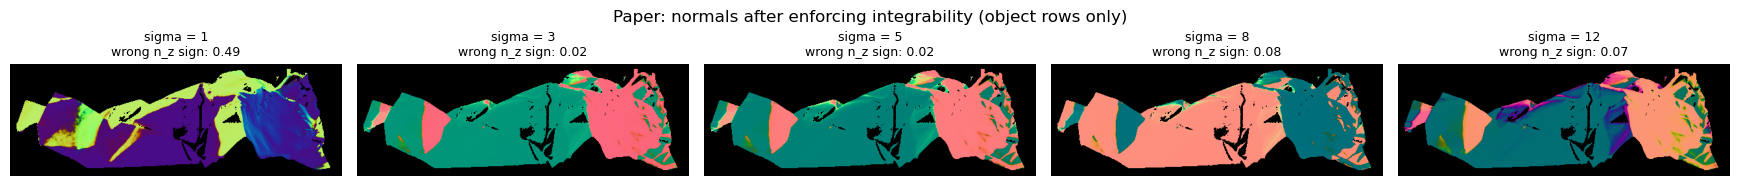

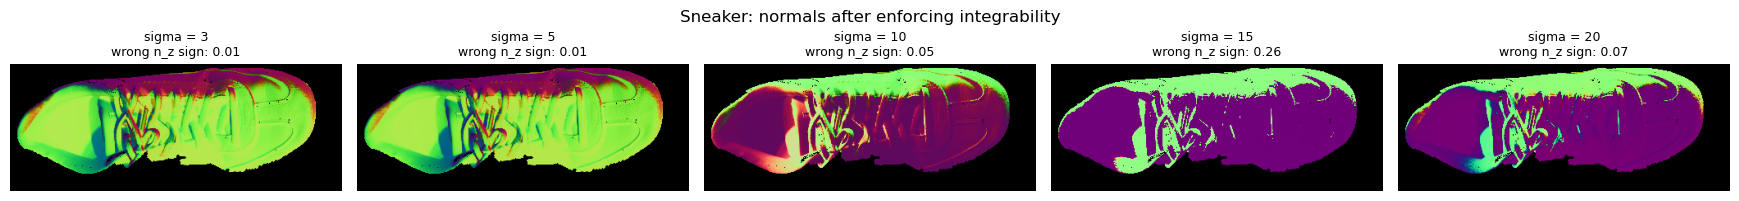

In [205]:
# Rank-3 factorization fitted on object pixels, then applied to every pixel
def factorize_rank3(I, mask):
    U, S, Vt = np.linalg.svd(I[:, mask], full_matrices=False)
    sqrt_singular = np.diag(np.sqrt(S[:3]))
    L_e = (U[:, :3] @ sqrt_singular).T

    # Least-squares pseudo-normals for all pixels
    B_e = np.linalg.pinv(L_e.T) @ I
    return L_e, B_e, S


# Fraction of object pixels whose n_z has the minority sign (no GBR can fix these)
def wrong_sign_fraction(B, mask):
    positive_fraction = np.mean(B[2, mask] > 0)
    return min(positive_fraction, 1 - positive_fraction)


# Normals after enforcing integrability, one panel per sigma
def show_sigma_sweep(B_e, height, width, mask, sigma_values, title, integrability_mask=None, filename=None):
    figure, axes = plt.subplots(1, len(sigma_values), figsize=(3.5 * len(sigma_values), 3.5 * height / width + 0.8))
    for index in range(len(sigma_values)):
        sigma = sigma_values[index]
        B_sigma, _ = enforce_integrability(B_e, height, width, sigma, integrability_mask)
        _, N_sigma = pseudonormals_to_albedo_normals(B_sigma)

        normal_image = normals_to_rgb(to_image(N_sigma, height, width))
        normal_image[~mask.reshape(height, width)] = 0
        axes[index].imshow(normal_image)
        axes[index].set_title(f"sigma = {sigma}\nwrong n_z sign: {wrong_sign_fraction(B_sigma, mask):.2f}", fontsize=9)
        axes[index].axis("off")
    figure.suptitle(title)
    plt.tight_layout()
    save_figure(figure, filename)
    plt.show()


# Integrate normals to depth, with zero gradients (flat) outside the object
def depth_inside_mask(normals, mask, height, width):
    depth_dx, depth_dy = normals_to_depth_gradients(normals, height, width)
    mask_image = mask.reshape(height, width)
    depth_dx[~mask_image] = 0
    depth_dy[~mask_image] = 0
    return integrate_poisson(depth_dx, depth_dy)


L_e_paper, B_e_paper, S_paper = factorize_rank3(I_paper, paper_mask)
print("Paper singular values:", np.round(S_paper, 2))
print(f"Paper sigma_3 / sigma_4: {S_paper[2] / S_paper[3]:.2f}")
# Chosen blur width (from the sweep below)
paper_sigma = 5
B_paper, Delta_paper = enforce_integrability(B_e_paper, H_paper, W_paper, paper_sigma, paper_mask)
_, N_paper = pseudonormals_to_albedo_normals(B_paper)
print(f"Paper wrong n_z sign: {wrong_sign_fraction(B_paper, paper_mask):.3f}")

L_e_sneaker, B_e_sneaker, S_sneaker = factorize_rank3(I_sneaker, sneaker_mask)
print("Sneaker singular values:", np.round(S_sneaker, 2))
print(f"Sneaker sigma_3 / sigma_4: {S_sneaker[2] / S_sneaker[3]:.2f}")
# Chosen blur width (from the sweep below)
sneaker_sigma = 5
B_sneaker, Delta_sneaker = enforce_integrability(B_e_sneaker, H_sneaker, W_sneaker, sneaker_sigma)
_, N_sneaker = pseudonormals_to_albedo_normals(B_sneaker)
print(f"Sneaker wrong n_z sign: {wrong_sign_fraction(B_sneaker, sneaker_mask):.3f}")

show_sigma_sweep(B_e_paper, H_paper, W_paper, paper_mask, [1, 3, 5, 8, 12],
                 "Paper: normals after enforcing integrability (object rows only)",
                 integrability_mask=paper_mask, filename="paper_sigma_comparison.png")
show_sigma_sweep(B_e_sneaker, H_sneaker, W_sneaker, sneaker_mask, [3, 5, 10, 15, 20],
                 "Sneaker: normals after enforcing integrability", filename="sneaker_sigma_comparison.png")

## Hand-tuning the GBR

Same starting point as Part 1 (average object normal faces the camera), then |λ| is picked by eye from a sweep. The paper should rise a few cm from a flat mat, and the sneaker's sole should be roughly straight. The sneaker needed the inside-out flip (sign of λ reversed). Outside the mask, the depth is set to the mat level for display.

Paper tilt to remove: 3.69 along x, -0.38 along y
Paper GBR: mu = -1.84, nu = 0.19, lam = -0.50
Sneaker tilt to remove: -0.04 along x, -0.87 along y
Sneaker GBR: mu = -0.02, nu = -0.44, lam = 0.50


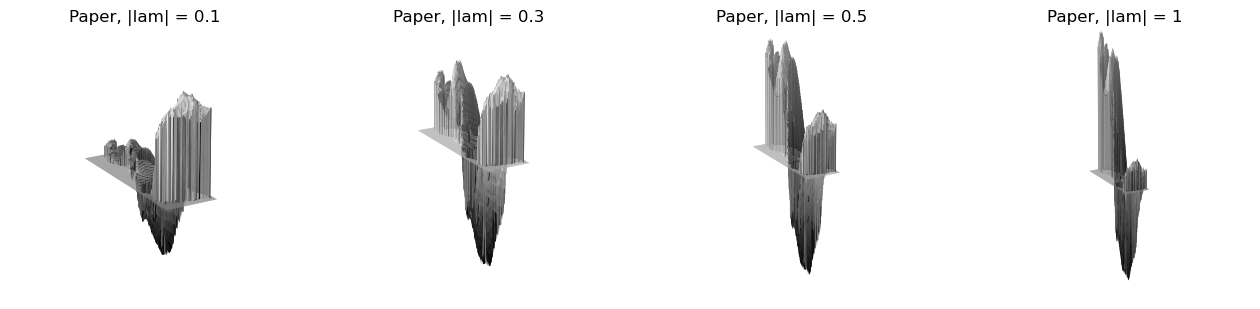

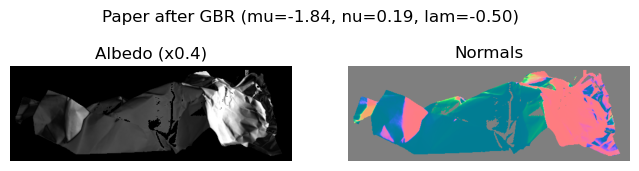

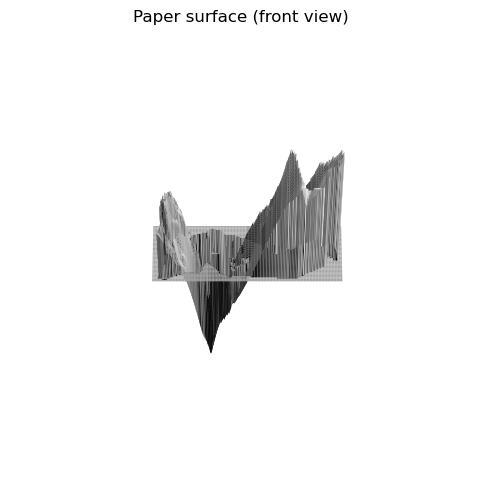

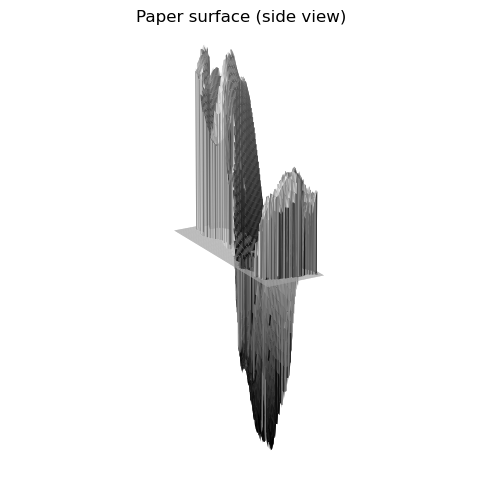

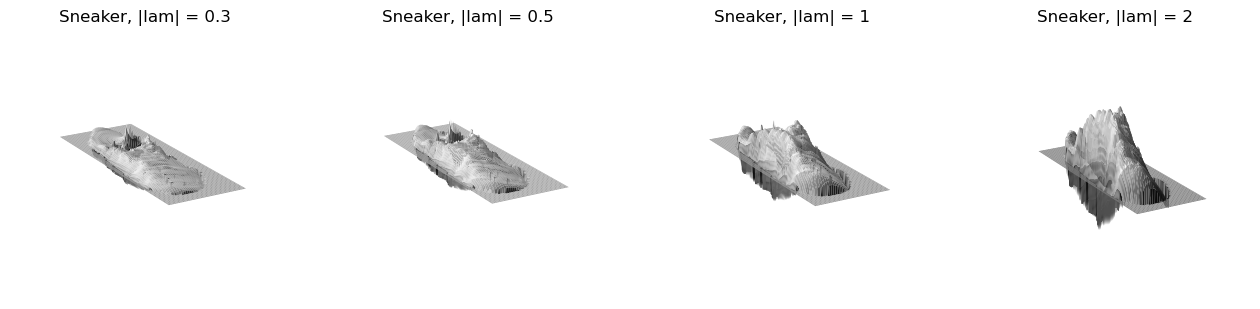

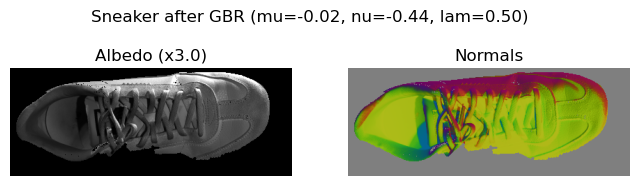

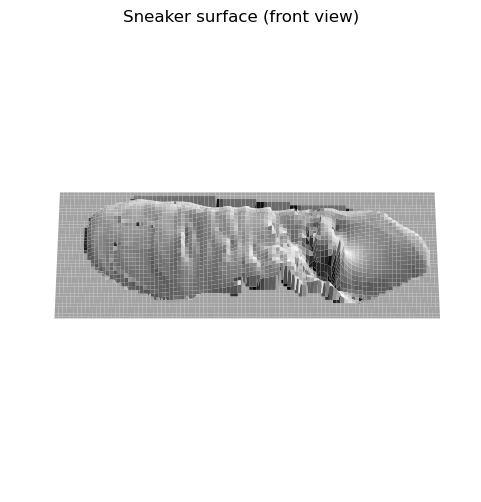

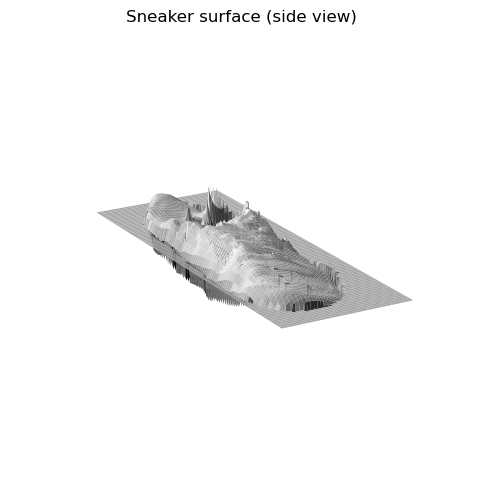

In [206]:
# Tilt that sends the average object normal to +z, and the sign of lam that keeps n_z positive
def tilt_from_mean_normal(normals, mask):
    mean_normal = np.mean(normals[:, mask], axis=1)
    tilt_x = mean_normal[0] / mean_normal[2]
    tilt_y = mean_normal[1] / mean_normal[2]
    lam_sign = np.sign(mean_normal[2])
    return tilt_x, tilt_y, lam_sign


# Set the background to the depth along the object's outline (the mat it rests on)
def flat_background(depth, mask_image):
    outline = mask_image & ~binary_erosion(mask_image)
    mat_depth = np.median(depth[outline])
    flattened = depth.copy()
    flattened[~mask_image] = mat_depth
    return flattened


# Apply a GBR, then return the albedo, normals, and depth (with a flat background)
def gbr_result(B, mask, height, width, mu, nu, lam):
    B_gbr = apply_gbr(B, mu, nu, lam)
    albedo, normals = pseudonormals_to_albedo_normals(B_gbr)
    depth = depth_inside_mask(normals, mask, height, width)
    depth = flat_background(depth, mask.reshape(height, width))
    return albedo, normals, depth


# Surfaces for several depth scales |lam|, with the average tilt removed
def show_gbr_sweep(B, mask, height, width, tilt_x, tilt_y, lam_sign, lam_magnitudes, title):
    depths = []
    titles = []
    for lam_magnitude in lam_magnitudes:
        lam = lam_sign * lam_magnitude
        _, _, depth = gbr_result(B, mask, height, width, lam * tilt_x, lam * tilt_y, lam)
        depths.append(depth)
        titles.append(f"{title}, |lam| = {lam_magnitude}")
    show_surfaces_in_row(depths, titles, elevation=20, azimuth=-30)


paper_tilt_x, paper_tilt_y, paper_lam_sign = tilt_from_mean_normal(N_paper, paper_mask)
print(f"Paper tilt to remove: {paper_tilt_x:.2f} along x, {paper_tilt_y:.2f} along y")
# Chosen depth scale (edit after the sweep below)
paper_lam = paper_lam_sign * 0.5
paper_mu = paper_lam * paper_tilt_x
paper_nu = paper_lam * paper_tilt_y
print(f"Paper GBR: mu = {paper_mu:.2f}, nu = {paper_nu:.2f}, lam = {paper_lam:.2f}")

A_paper_gbr, N_paper_gbr, Z_paper_gbr = gbr_result(B_paper, paper_mask, H_paper, W_paper,
                                                   paper_mu, paper_nu, paper_lam)

sneaker_tilt_x, sneaker_tilt_y, sneaker_lam_sign = tilt_from_mean_normal(N_sneaker, sneaker_mask)
print(f"Sneaker tilt to remove: {sneaker_tilt_x:.2f} along x, {sneaker_tilt_y:.2f} along y")
# Chosen depth scale (edit after the sweep below)
sneaker_lam = -sneaker_lam_sign * 0.5   # flipped (G_F), see the sweep
sneaker_mu = sneaker_lam * sneaker_tilt_x
sneaker_nu = sneaker_lam * sneaker_tilt_y
print(f"Sneaker GBR: mu = {sneaker_mu:.2f}, nu = {sneaker_nu:.2f}, lam = {sneaker_lam:.2f}")

A_sneaker_gbr, N_sneaker_gbr, Z_sneaker_gbr = gbr_result(B_sneaker, sneaker_mask, H_sneaker, W_sneaker,
                                                         sneaker_mu, sneaker_nu, sneaker_lam)

show_gbr_sweep(B_paper, paper_mask, H_paper, W_paper, paper_tilt_x, paper_tilt_y, paper_lam_sign,
               [0.1, 0.3, 0.5, 1], "Paper")
albedo_scale = round(1 / np.percentile(A_paper_gbr[paper_mask], 99), 1)
show_albedo_and_normals(A_paper_gbr * paper_mask, N_paper_gbr * paper_mask, H_paper, W_paper,
                        f"Paper after GBR (mu={paper_mu:.2f}, nu={paper_nu:.2f}, lam={paper_lam:.2f})",
                        albedo_scale=albedo_scale, filename="paper_albedo_normals.png")
show_surface(Z_paper_gbr, "Paper surface (front view)", elevation=60, azimuth=90,
             filename="paper_surface_front.png")
show_surface(Z_paper_gbr, "Paper surface (side view)", elevation=20, azimuth=-30)

# The mean-n_z sign gives a bowl sunk into the mat, so flip it (G_F)
show_gbr_sweep(B_sneaker, sneaker_mask, H_sneaker, W_sneaker, sneaker_tilt_x,
               sneaker_tilt_y, -sneaker_lam_sign,
               [0.3, 0.5, 1, 2], "Sneaker")
albedo_scale = round(1 / np.percentile(A_sneaker_gbr[sneaker_mask], 99), 1)
show_albedo_and_normals(A_sneaker_gbr * sneaker_mask, N_sneaker_gbr * sneaker_mask, H_sneaker, W_sneaker,
                        f"Sneaker after GBR (mu={sneaker_mu:.2f}, nu={sneaker_nu:.2f}, lam={sneaker_lam:.2f})",
                        albedo_scale=albedo_scale, filename="sneaker_albedo_normals.png")
show_surface(Z_sneaker_gbr, "Sneaker surface (front view)", elevation=60, azimuth=90,
             filename="sneaker_surface_front.png")
show_surface(Z_sneaker_gbr, "Sneaker surface (side view)", elevation=20, azimuth=-30,
             filename="sneaker_surface_side.png")

## Relighting under a new light

Render $\max(0,\, a\, n \cdot l)$ for a light that was not captured. The new light is chosen in the recovered (GBR) frame, next to captured image 1 for comparison.

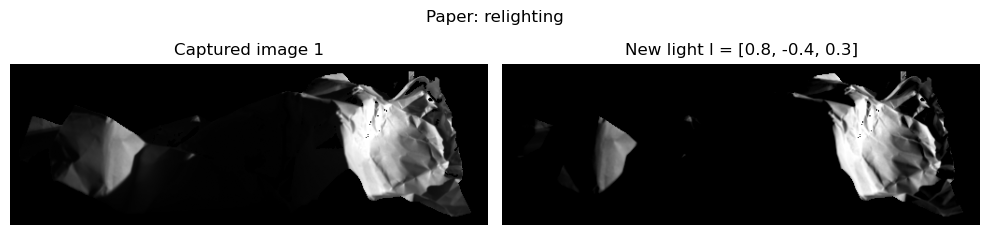

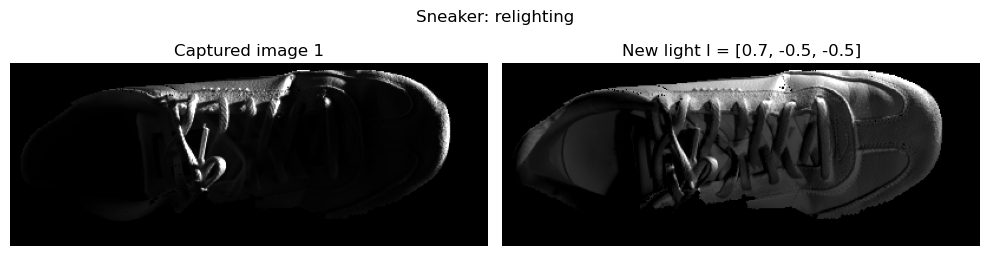

In [207]:
# Lambertian rendering of albedo/normals under a directional light
def render_lambertian(albedo, normals, light_direction, height, width):
    light_direction = light_direction / np.linalg.norm(light_direction)
    shading = light_direction @ normals          # n . l for every pixel
    radiance = albedo * shading
    radiance = np.maximum(radiance, 0)           # clip back-facing pixels
    return to_image(radiance, height, width)


# Captured image next to a rendering with a new light
def show_relighting(captured, new_render, mask_image, new_light, title, filename=None):
    images = [captured, new_render]
    titles = ["Captured image 1",
              f"New light l = {np.round(new_light, 2).tolist()}"]
    height, width = captured.shape
    figure, axes = plt.subplots(1, 2, figsize=(10, 5 * height / width + 0.8))
    for index in range(2):
        image = images[index] * mask_image
        # Same brightness scale for each panel (99th percentile of the object)
        scale = np.percentile(image[mask_image], 99)
        axes[index].imshow(np.clip(image / scale, 0, 1), cmap="gray")
        axes[index].set_title(titles[index])
        axes[index].axis("off")
    figure.suptitle(title)
    plt.tight_layout()
    save_figure(figure, filename)
    plt.show()


# Low raking light (small z) to bring out the creases
paper_new_light = np.array([0.8, -0.4, 0.3])
paper_mask_image = paper_mask.reshape(H_paper, W_paper)

paper_relit = render_lambertian(A_paper_gbr, N_paper_gbr, paper_new_light, H_paper, W_paper)
paper_captured = to_image(I_paper[0], H_paper, W_paper)

# lam was flipped for the sneaker, so the new light needs z < 0
sneaker_new_light = np.array([0.7, -0.5, -0.5])
sneaker_mask_image = sneaker_mask.reshape(H_sneaker, W_sneaker)

sneaker_relit = render_lambertian(A_sneaker_gbr, N_sneaker_gbr, sneaker_new_light, H_sneaker, W_sneaker)
sneaker_captured = to_image(I_sneaker[0], H_sneaker, W_sneaker)

show_relighting(paper_captured, paper_relit, paper_mask_image, paper_new_light,
                "Paper: relighting", filename="paper_relit.png")
show_relighting(sneaker_captured, sneaker_relit, sneaker_mask_image, sneaker_new_light,
                "Sneaker: relighting", filename="sneaker_relit.png")